# 10 — Inférence CAE sur les trois catégories (US-03-05, ST-03-05-02 / IDL-36)

Vérifie `src/inference/cae_inference.py` avec les **vrais checkpoints** entraînés :

| Catégorie | Expérience | Checkpoint (Output Kaggle ajouté en Input) |
|---|---|---|
| bottle | `cae-bottle/EXP-002` (Mouad) | `06-cae-bottle-training` v`368423258` → `bottle_best.pth` |
| hazelnut | `cae-hazelnut/EXP-001` (Marwane) | `industrialdefect-ai-cae-hazelnut-training` → `best_model.pt` |
| transistor | `cae-transistor/EXP-001` (Zakaria) | `06-cae-train` v`368211534` → `cae/transistor/best_model.pt` |

Contrôles par catégorie :
1. **Bon checkpoint** : SHA-256 identique à la fiche d'expérience (bottle, hazelnut), chargement strict, aucun réentraînement.
2. **Sorties conformes** : carte `[256, 256]`, reconstruction `[3, 256, 256]` dans `[0, 1]`, score fini ≥ 0, sur toute la validation.
3. **Cohérence** : la MSE moyenne recalculée par le moteur d'inférence sur la validation = la meilleure val MSE de l'entraînement.
4. **Carte d'anomalie** : sur des images de validation avec un **défaut synthétique** (carré de bruit), le score augmente et le pic de la carte tombe sur le défaut.

> **Protocole** : le split `test` est réservé à l'évaluation finale (`split_protocol.json`). Ce notebook n'utilise **que la validation** (images normales) ; les défauts sont synthétiques. Aucun seuil n'est calibré ici (US-05-02).

In [1]:
# ===== Paramètres =====
REPO_URL = "https://github.com/MRdrissi/industrial-defect-ai.git"
GIT_REF = "feature/us-03-05-cae-inference"   # branche contenant src/inference/cae_inference.py

CATEGORIES = ("bottle", "hazelnut", "transistor")
N_SYNTHETIC = 6        # images de validation par catégorie pour le défaut synthétique
PATCH = 32             # côté du carré de bruit (pixels, image 256x256)
SEED = 42
VAL_MSE_RTOL = 1e-3    # tolérance relative sur la val MSE recalculée

import hashlib, json, shutil, subprocess, sys, platform
from datetime import datetime, timezone
from pathlib import Path

INPUT = Path("/kaggle/input")
OUT = Path("/kaggle/working/us-03-05")
OUT.mkdir(parents=True, exist_ok=True)

REPO_DIR = Path("/kaggle/temp/industrial-defect-ai")
if REPO_DIR.exists():
    shutil.rmtree(REPO_DIR)
subprocess.run(["git", "clone", "--quiet", "--branch", GIT_REF, REPO_URL, str(REPO_DIR)], check=True)
GIT_COMMIT = subprocess.run(["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"],
                            check=True, capture_output=True, text=True).stdout.strip()
sys.path.insert(0, str(REPO_DIR))
print("Branche :", GIT_REF)
print("Commit  :", GIT_COMMIT)

Branche : feature/us-03-05-cae-inference
Commit  : f12105d7c66a557db1ca2ccb57c28d524d42d64e


In [2]:
import numpy as np
import torch

from src.data.mvtec_dataset import MVTecDataset
from src.data.transforms import MVTecTransform
from src.inference.cae_inference import CAEInference, CAEInferenceConfig, extract_state_dict

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CONFIG_PATH = REPO_DIR / "experiments/configs/cae_baseline.json"
print("Device :", DEVICE, "| torch", torch.__version__)


def sha256(path: Path) -> str:
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def read_run(rel: str) -> dict:
    return json.loads((REPO_DIR / "experiments/runs" / rel).read_text("utf-8"))


# ===== Fiches d'expérience (source de vérité : le repo) =====
runs = {
    "bottle": read_run("cae-bottle/EXP-002.json"),
    "hazelnut": read_run("cae-hazelnut/EXP-001.json"),
    "transistor": read_run("cae-transistor/EXP-001.json"),
}
EXPECTED = {
    "bottle": {"experiment": "cae-bottle/EXP-002",
               "sha256": runs["bottle"]["artifacts"]["model_sha256"],
               "best_val_mse": runs["bottle"]["metrics"]["best_val_mse"]},
    "hazelnut": {"experiment": "cae-hazelnut/EXP-001",
                 "sha256": runs["hazelnut"]["artifacts"]["model_sha256"],
                 "best_val_mse": runs["hazelnut"]["metrics"]["best_val_mse"]},
    "transistor": {"experiment": "cae-transistor/EXP-001",
                   "sha256": None,  # non enregistré dans la fiche : repéré par son chemin
                   "best_val_mse": runs["transistor"]["training_results"]["best_val_loss"]},
}

# ===== Localiser les checkpoints dans les Inputs =====
candidates = [p for p in INPUT.rglob("*") if p.suffix in (".pt", ".pth") and p.is_file()]
hashes = {p: sha256(p) for p in candidates}
print(f"{len(candidates)} fichier(s) .pt/.pth trouvés dans /kaggle/input")

CHECKPOINTS = {}
for cat in CATEGORIES:
    expected_sha = EXPECTED[cat]["sha256"]
    if expected_sha:
        found = [p for p, h in hashes.items() if h == expected_sha]
    else:
        found = [p for p in candidates
                 if p.name == "best_model.pt" and p.parent.name == cat
                 and (p.parent / "run_info.json").is_file()]
    assert len(found) >= 1, (
        f"{cat} : checkpoint introuvable. Ajoute l'Output du notebook d'entraînement en Input "
        f"(bonne version !). Candidats : {[str(p) for p in candidates]}")
    CHECKPOINTS[cat] = found[0]
    print(f"  {cat:<10} -> {found[0]}")


# ===== Localiser MVTec AD =====
def find_mvtec_root() -> Path:
    roots = {p.parent for p in INPUT.rglob("bottle")
             if p.is_dir() and all((p / d).is_dir() for d in ("train", "test", "ground_truth"))}
    assert len(roots) == 1, f"Racines MVTec trouvées : {roots}"
    return roots.pop()


DATASET_ROOT = find_mvtec_root()
print("MVTec AD :", DATASET_ROOT)

Device : cuda | torch 2.11.0+cu130
3 fichier(s) .pt/.pth trouvés dans /kaggle/input
  bottle     -> /kaggle/input/notebooks/mouadfekkak/06-cae-bottle-training/cae_bottle_EXP-002_uurtonr7/bottle_best.pth
  hazelnut   -> /kaggle/input/notebooks/marwanedrissi/industrialdefect-ai-cae-hazelnut-training/cae/hazelnut/hazelnut-baseline-001/best_model.pt
  transistor -> /kaggle/input/notebooks/zakariaelbergui/06-cae-train/cae/transistor/best_model.pt
MVTec AD : /kaggle/input/datasets/ipythonx/mvtec-ad


In [3]:
# ===== 1. Chargement (aucun réentraînement) et contrôle d'intégrité =====
engines, load_info = {}, {}
for cat in CATEGORIES:
    path = CHECKPOINTS[cat]
    raw = torch.load(path, map_location="cpu", weights_only=True)
    fmt = "dict + model_state_dict" if "model_state_dict" in raw else "poids seuls"
    n_tensors = len(extract_state_dict(raw))

    engine = CAEInference.from_checkpoint(cat, CONFIG_PATH, path, device=DEVICE)
    n_params = sum(p.numel() for p in engine.model.parameters())
    assert not engine.model.training

    load_info[cat] = {
        "experiment": EXPECTED[cat]["experiment"],
        "checkpoint": str(path.relative_to(INPUT)),
        "checkpoint_format": fmt,
        "sha256": hashes[path],
        "sha256_matches_run": (hashes[path] == EXPECTED[cat]["sha256"]) if EXPECTED[cat]["sha256"] else None,
        "model_name": engine.model_name,
        "parameters": n_params,
        "state_dict_tensors": n_tensors,
    }
    engines[cat] = engine
    print(f"{cat:<10} | format : {fmt:<24} | {n_params:,} paramètres | "
          f"SHA OK : {load_info[cat]['sha256_matches_run']}")

bottle     | format : dict + model_state_dict  | 855,619 paramètres | SHA OK : True
hazelnut   | format : dict + model_state_dict  | 855,619 paramètres | SHA OK : True
transistor | format : poids seuls              | 855,619 paramètres | SHA OK : None


In [4]:
# ===== 2 + 3. Sorties sur toute la validation et cohérence avec l'entraînement =====
BATCH = 16
transform = MVTecTransform(size=(256, 256), profile="cae")
val_sets, val_checks = {}, {}

for cat in CATEGORIES:
    ds = MVTecDataset(DATASET_ROOT, REPO_DIR / f"docs/data/us-02-03/{cat}_manifest.csv", cat, "val", transform)
    val_sets[cat] = ds
    scores, mses = [], []
    for start in range(0, len(ds), BATCH):
        images = torch.stack([ds[i]["image"] for i in range(start, min(start + BATCH, len(ds)))])
        for r in engines[cat].predict_batch(images):
            assert tuple(r.anomaly_map.shape) == (256, 256)
            assert tuple(r.reconstruction.shape) == (3, 256, 256)
            assert torch.isfinite(r.anomaly_map).all() and r.anomaly_map.min() >= 0
            assert 0.0 <= r.reconstruction.min() and r.reconstruction.max() <= 1.0
            assert np.isfinite(r.score) and r.score >= 0
            scores.append(r.score)
            mses.append(r.extras["mean_mse"])

    recomputed = float(np.mean(mses))
    expected = EXPECTED[cat]["best_val_mse"]
    rel_gap = abs(recomputed - expected) / expected
    val_checks[cat] = {
        "val_images": len(ds),
        "expected_val_mse": expected,
        "recomputed_val_mse": recomputed,
        "relative_gap": rel_gap,
        "passed": rel_gap <= VAL_MSE_RTOL,
        "val_score_max": {"mean": float(np.mean(scores)), "std": float(np.std(scores)),
                          "min": float(np.min(scores)), "max": float(np.max(scores))},
    }
    print(f"{cat:<10} | {len(ds):>3} images | val MSE attendue {expected:.10f} | "
          f"recalculée {recomputed:.10f} | écart relatif {rel_gap:.2e}")
    assert val_checks[cat]["passed"], f"{cat} : la val MSE ne correspond pas -> mauvais checkpoint ou mauvais prétraitement"

bottle     |  42 images | val MSE attendue 0.0003680491 | recalculée 0.0003680491 | écart relatif 7.34e-08
hazelnut   |  78 images | val MSE attendue 0.0002059518 | recalculée 0.0002059518 | écart relatif 5.30e-08
transistor |  43 images | val MSE attendue 0.0006124485 | recalculée 0.0006124485 | écart relatif 4.20e-08


In [5]:
# ===== 4. Défaut synthétique : le score monte et la carte localise le défaut =====
rng = np.random.default_rng(SEED)


def add_noise_patch(image: torch.Tensor, top: int, left: int) -> torch.Tensor:
    out = image.clone()
    noise = torch.from_numpy(rng.random((3, PATCH, PATCH), dtype=np.float32))
    out[:, top:top + PATCH, left:left + PATCH] = noise
    return out


synthetic, examples = {}, {}
for cat in CATEGORIES:
    ds = val_sets[cat]
    idx = np.linspace(0, len(ds) - 1, N_SYNTHETIC, dtype=int)
    rows = []
    for k, i in enumerate(idx):
        image = ds[int(i)]["image"]
        # carré placé dans la zone centrale (là où se trouve l'objet)
        top, left = (int(v) for v in rng.integers(64, 256 - 64 - PATCH, size=2))
        defect = add_noise_patch(image, top, left)
        normal_r, defect_r = engines[cat].predict(image), engines[cat].predict(defect)
        peak_r, peak_c = divmod(int(defect_r.anomaly_map.argmax()), 256)
        margin = 8
        inside = (top - margin <= peak_r < top + PATCH + margin) and (left - margin <= peak_c < left + PATCH + margin)
        rows.append({"image_path": ds[int(i)]["image_path"], "patch_top_left": [top, left],
                     "score_normal": normal_r.score, "score_defect": defect_r.score,
                     "ratio": defect_r.score / max(normal_r.score, 1e-12),
                     "peak": [peak_r, peak_c], "peak_on_defect": bool(inside)})
        if k < 3:
            examples.setdefault(cat, []).append((image, normal_r, defect, defect_r, (top, left)))

    synthetic[cat] = {
        "images": len(rows),
        "score_increases": sum(r["score_defect"] > r["score_normal"] for r in rows),
        "peak_on_defect": sum(r["peak_on_defect"] for r in rows),
        "median_ratio": float(np.median([r["ratio"] for r in rows])),
        "details": rows,
    }
    s = synthetic[cat]
    print(f"{cat:<10} | score en hausse : {s['score_increases']}/{s['images']} | "
          f"pic sur le défaut : {s['peak_on_defect']}/{s['images']} | ratio médian ×{s['median_ratio']:.1f}")

bottle     | score en hausse : 6/6 | pic sur le défaut : 6/6 | ratio médian ×10.7
hazelnut   | score en hausse : 6/6 | pic sur le défaut : 6/6 | ratio médian ×44.3
transistor | score en hausse : 6/6 | pic sur le défaut : 6/6 | ratio médian ×6.8


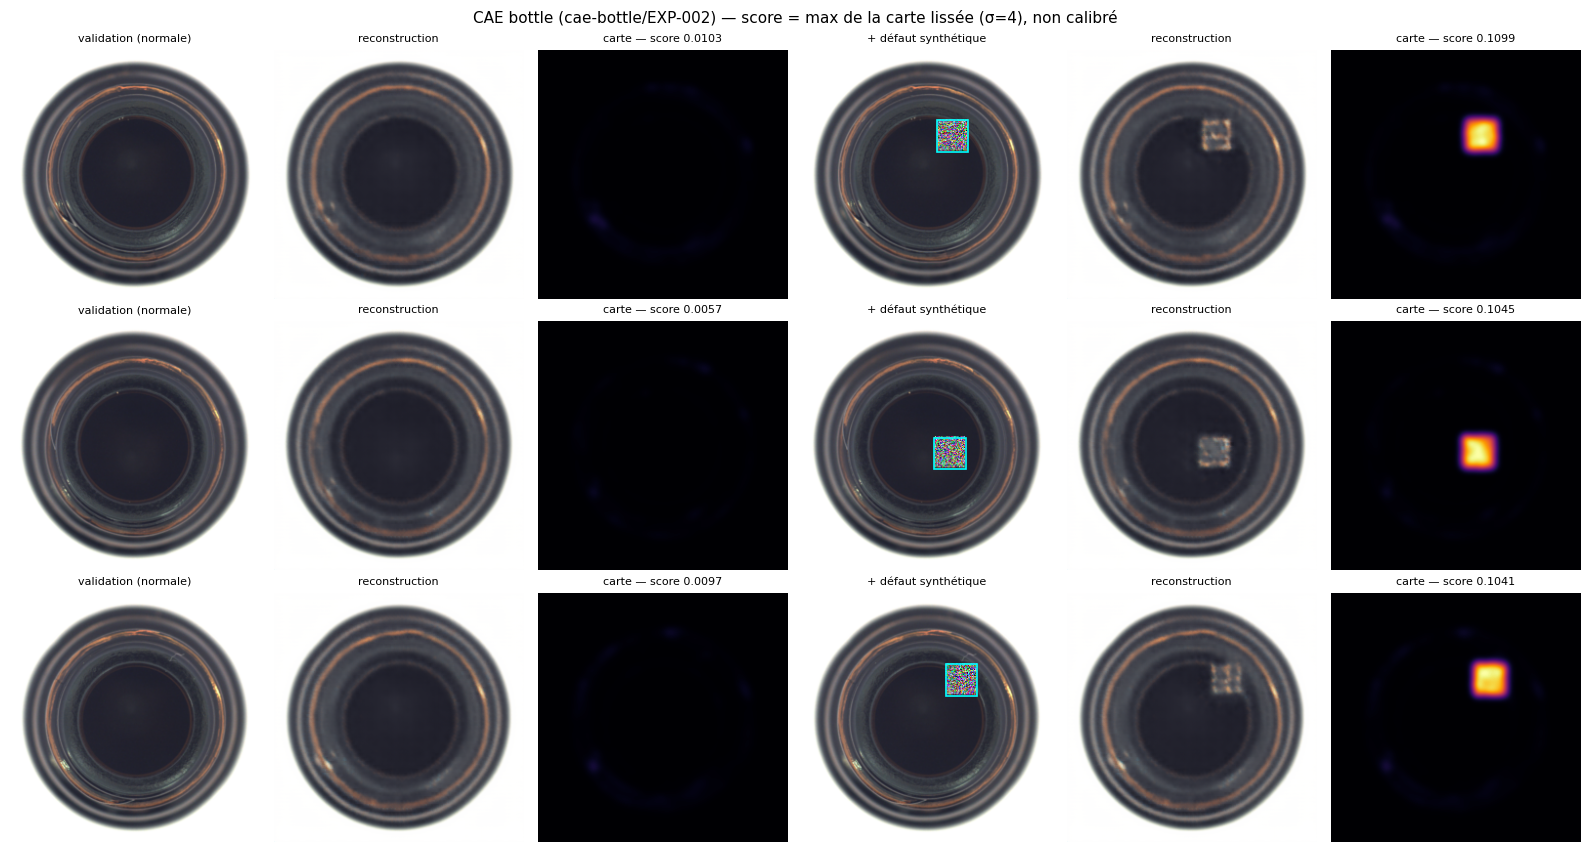

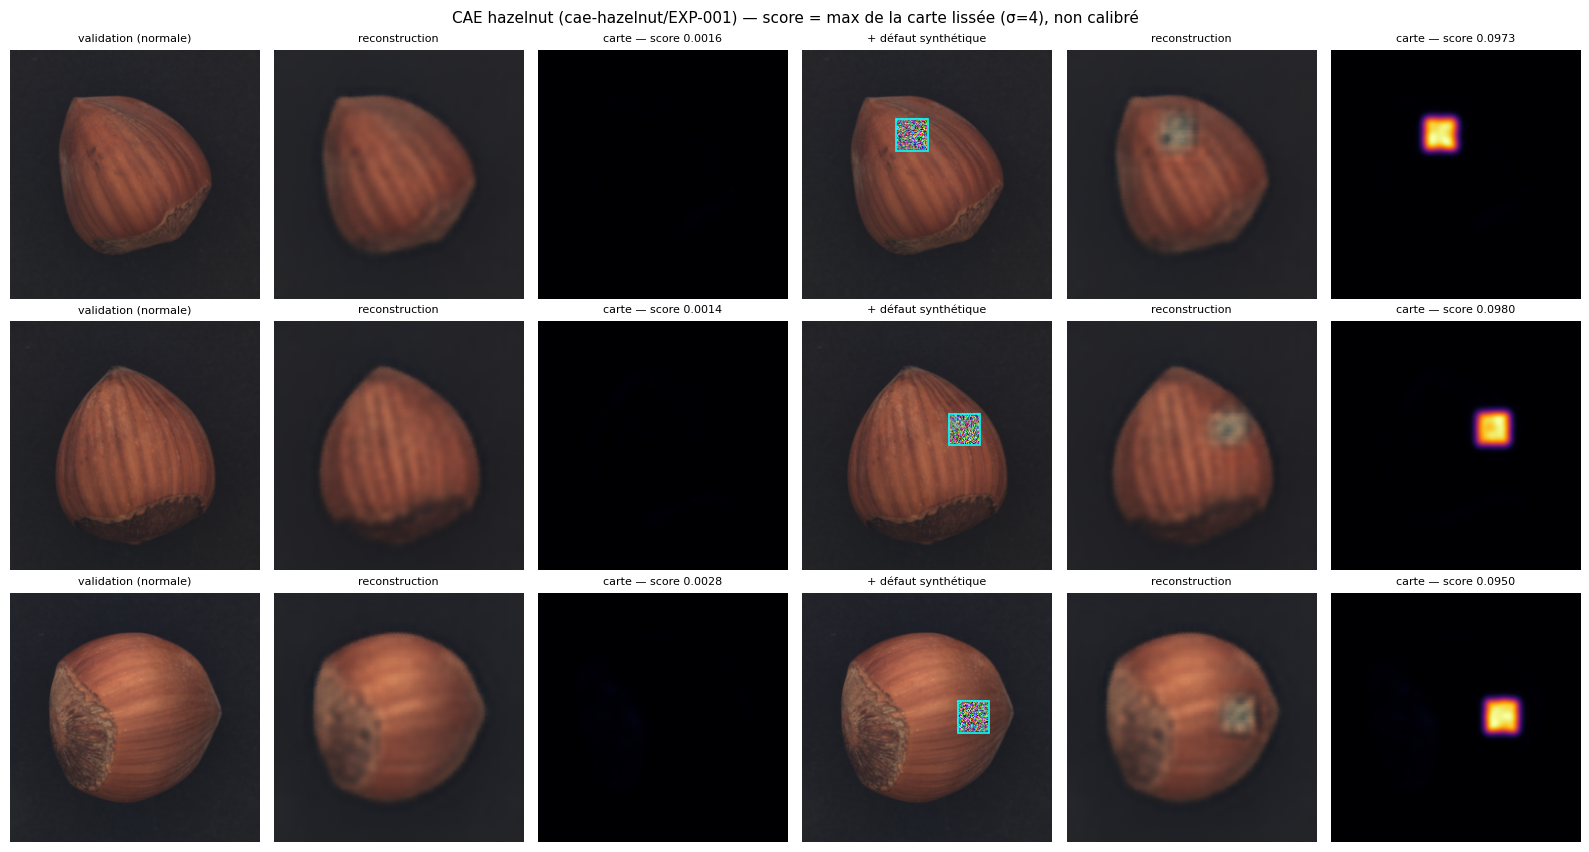

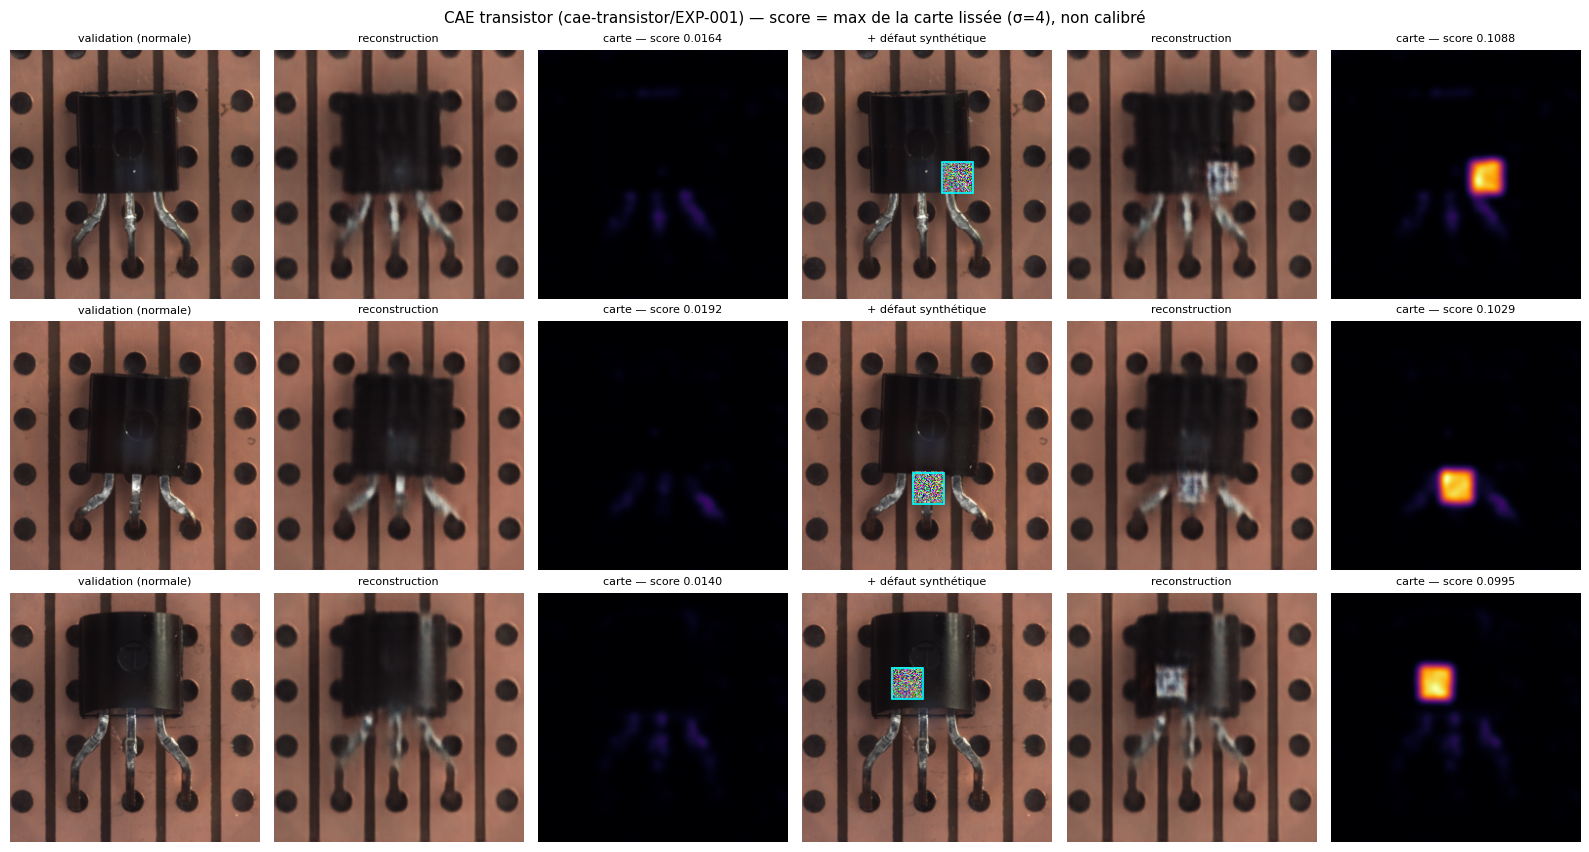

In [6]:
# ===== Figures : image, reconstruction, carte d'anomalie (normal puis défaut synthétique) =====
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches


def show(ax, data, title, cmap=None, vmax=None):
    ax.imshow(data, cmap=cmap, vmin=0 if cmap else None, vmax=vmax)
    ax.set_title(title, fontsize=8)
    ax.axis("off")


for cat in CATEGORIES:
    ex = examples[cat]
    fig, axes = plt.subplots(len(ex), 6, figsize=(16, 2.9 * len(ex)))
    for row, (image, nr, defect, dr, (top, left)) in enumerate(ex):
        vmax = float(dr.anomaly_map.max())  # même échelle pour les deux cartes de la ligne
        show(axes[row, 0], image.permute(1, 2, 0).numpy(), "validation (normale)")
        show(axes[row, 1], nr.reconstruction.permute(1, 2, 0).numpy(), "reconstruction")
        show(axes[row, 2], nr.anomaly_map.numpy(), f"carte — score {nr.score:.4f}", "inferno", vmax)
        show(axes[row, 3], defect.permute(1, 2, 0).numpy(), "+ défaut synthétique")
        axes[row, 3].add_patch(mpatches.Rectangle((left, top), PATCH, PATCH, fill=False, ec="cyan", lw=1.2))
        show(axes[row, 4], dr.reconstruction.permute(1, 2, 0).numpy(), "reconstruction")
        show(axes[row, 5], dr.anomaly_map.numpy(), f"carte — score {dr.score:.4f}", "inferno", vmax)
    fig.suptitle(f"CAE {cat} ({EXPECTED[cat]['experiment']}) — score = max de la carte lissée (σ=4), non calibré",
                 fontsize=11)
    fig.tight_layout()
    fig.savefig(OUT / f"{cat}_inference.png", dpi=110, bbox_inches="tight")
    plt.show()

In [7]:
# ===== Rapport =====
report = {
    "user_story": "US-03-05",
    "subtask": "ST-03-05-02 (IDL-36)",
    "checked_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "code": {"repo": REPO_URL, "git_ref": GIT_REF, "git_commit": GIT_COMMIT},
    "environment": {"python": platform.python_version(), "torch": torch.__version__, "device": str(DEVICE)},
    "inference_config": {"smoothing_sigma": CAEInferenceConfig().smoothing_sigma,
                         "score_method": CAEInferenceConfig().score_method, "calibrated": False},
    "protocol": "validation uniquement (images normales) + défauts synthétiques ; split test non utilisé",
    "synthetic_defect": {"type": "carré de bruit uniforme", "size_px": PATCH, "seed": SEED},
    "retrained": False,
    "categories": {cat: {"loading": load_info[cat], "validation": val_checks[cat],
                         "synthetic": synthetic[cat]} for cat in CATEGORIES},
}
report["status"] = "OK" if all(val_checks[c]["passed"] for c in CATEGORIES) else "FAILED"
(OUT / "inference_report.json").write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"{'catégorie':<11}{'format':<26}{'val MSE recalculée':>20}{'écart rel.':>12}{'score ↑':>9}{'pic OK':>8}")
for cat in CATEGORIES:
    v, s = val_checks[cat], synthetic[cat]
    print(f"{cat:<11}{load_info[cat]['checkpoint_format']:<26}{v['recomputed_val_mse']:>20.10f}"
          f"{v['relative_gap']:>12.1e}{s['score_increases']:>5}/{s['images']}{s['peak_on_defect']:>5}/{s['images']}")
print("\nStatut :", report["status"])
print("Fichiers :", sorted(p.name for p in OUT.iterdir()))

catégorie  format                      val MSE recalculée  écart rel.  score ↑  pic OK
bottle     dict + model_state_dict           0.0003680491     7.3e-08    6/6    6/6
hazelnut   dict + model_state_dict           0.0002059518     5.3e-08    6/6    6/6
transistor poids seuls                       0.0006124485     4.2e-08    6/6    6/6

Statut : OK
Fichiers : ['bottle_inference.png', 'hazelnut_inference.png', 'inference_report.json', 'transistor_inference.png']
